In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

sns.set_theme(style="whitegrid") 

In [2]:
df = pd.read_csv("insurance.csv")
df["age"] = df["age"].fillna(df["age"].median())


df = pd.get_dummies(df, drop_first=True)

X = df.drop("charges", axis=1)
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape)

(1070, 8)


Подготовила данные о медицинской страховке для обучения модели, которая предсказывает размер страховых выплат. Пропуски в возрасте заполнила медианой, превратила текстовые категории пол, регион, курение в числовые признаки и разделила данные на то, что предсказываемые выплаты и то, по чему предсказываю. Затем выборку разделила на обучающую 80% и тестовую 20% части, а все числовые признаки привели к единому масштабу, чтобы модель не отдавала предпочтение признакам с большими числами. Результат `(1070, 8)` говорит о том, что после всех преобразований обучающая выборка содержит 1070 примеров и 8 признаков.

In [4]:
median_class = y_train.median()
y_train_class = (y_train>median_class).astype(int)
y_test_class = (y_test>median_class).astype(int)

clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train, y_train_class)

sample_probs = clf.predict_proba(X_test[:5])[:, 1]
sample_preds = clf.predict(X_test[:5])

results_class = pd.DataFrame(
    {
        "Вероятность (Сигмоида)":sample_probs,
        "Класс (Порог 0.5)":sample_preds,
        "Факт":y_test_class.iloc[:5].values,
    }
)
display(results_class.round(3))
print(f"Accuracy: {accuracy_score(y_test_class, clf.predict(X_test)):.4f}")

,Вероятность (Сигмоида),Класс (Порог 0.5),Факт
0,0.558,1,0
1,0.190,0,0
2,1.000,1,1
3,0.485,0,0
4,0.978,1,1


Accuracy: 0.9104


Модель отвечает на вопрос, будут ли выплаты выше или ниже медианы. Для этого значение charges преобразуется в классы 1 и 0 относительно медиан тренировочной выборки. В таблице для первых пяти примеров показаны: предсказанная вероятность(выход сигмоды), итоговый класс модели и реальный факт. Из этих пяти примеров модель ошиблась только в первом, т.к. предсказала 1 при вероятности 0,558, а факт 0, в остальных совпало. Главный результат Accuracy=91,04%, модель правильно определяет превышают ли страховые выплаты меданный уровень.

In [6]:
start_ols = time.time()
ols = LinearRegression()
ols.fit(X_train, y_train)
time_ols = time.time()-start_ols
pred_ols = ols.predict(X_test)

start_sgd = time.time()
sgd = SGDRegressor(
    max_iter=1000, tol=1e-3, eta0=0.01, learning_rate="adaptive", random_state=42
)
sgd.fit(X_train, y_train)
time_sgd = time.time()-start_sgd
pred_sgd = sgd.predict(X_test)

rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
r2_ols = r2_score(y_test, pred_ols)

rmse_sgd = np.sqrt(mean_squared_error(y_test, pred_sgd))
r2_sgd = r2_score(y_test, pred_sgd)

print(f"МНК (Аналитический): RMSE = ${rmse_ols:,.2f} | R2 = {r2_ols:,.2f} | Время = {time_ols:.5f} сек")
print(f"SGD (Интеративный): RMSE = ${rmse_sgd:,.2f} | R2 = {r2_sgd:,.2f} | Время = {time_sgd:.5f} сек")

МНК (Аналитический): RMSE = $5,796.28 | R2 = 0.78 | Время = 0.00503 сек
SGD (Интеративный): RMSE = $5,796.14 | R2 = 0.78 | Время = 0.07395 сек


Этот код сравнивает две реализации линейной регрессии — аналитический метод МНК и итеративный SGD  и показывает, что по качеству они практически идентичны: RMSE составляет 5,796 долларов у обоих, а R2=0.78, то есть обе модели объясняют около 78% разброса страховых выплат. Единственное заметное различие — скорость: МНК обучился за 0.005 сек, а SGD — за 0.074 сек. 

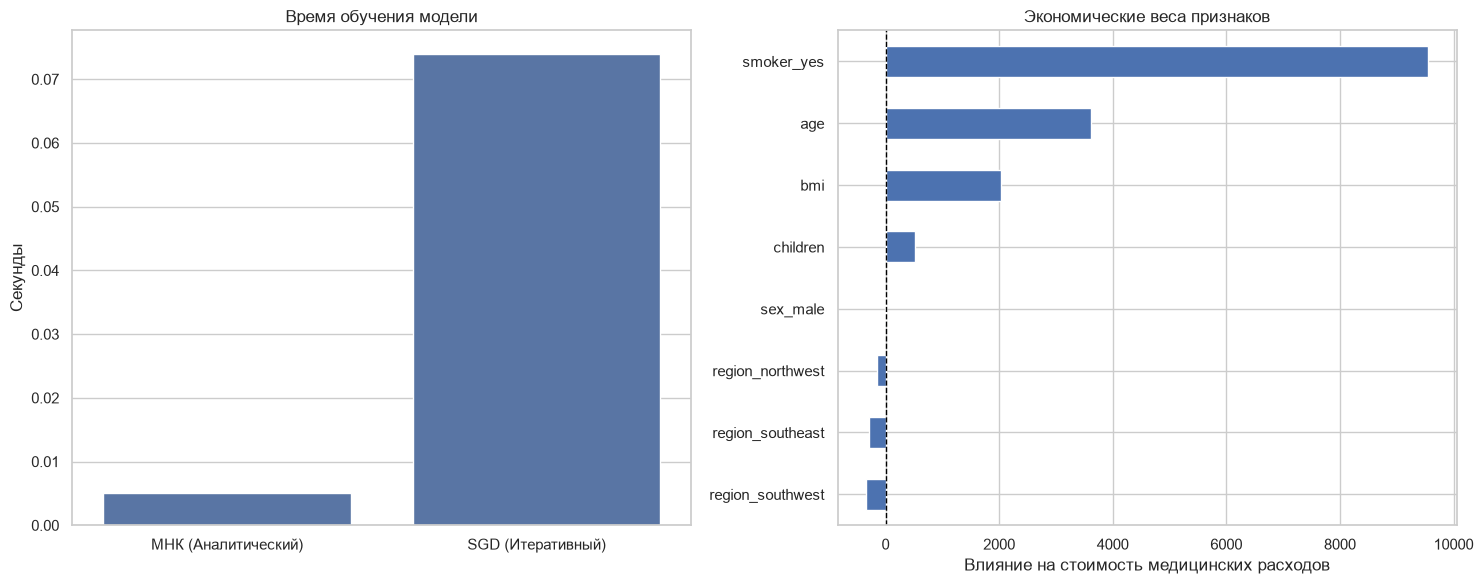

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))


sns.barplot(
    x=["МНК (Аналитический)", "SGD (Итеративный)"],
    y=[time_ols, time_sgd],
    ax=axes[0],
)
axes[0].set_title("Время обучения модели")
axes[0].set_ylabel("Секунды")


weights = pd.Series(ols.coef_, index=X.columns).sort_values()
weights.plot(kind="barh", ax=axes[1])        # было "brah" → "barh", weight → weights
axes[1].set_title("Экономические веса признаков")
axes[1].set_xlabel("Влияние на стоимость медицинских расходов")
axes[1].axvline(0, color="black", linestyle="--", lw=1)

plt.tight_layout()
plt.show()

Два графика, которые подводят итог сравнения моделей и раскрывают суть линеной регрессии. График "Время обучения модели" показывает, что SGD в 15 раз выше столбца МНК, т.е. аналитический метод обучается быстрее. Другой график "Экономические веса признаков" показывает, как каждый фактор влияет на итоговую стоимость медицинских расходов. Большее вллиянее оказывает курение, возраст и индекс массы тела, а пол, дети и регион имеют наименьшее влияние. Графики показывают, что аналитический МНК лучше по скорости, а самыми значимыми факторами для предсказания страховых выплат являются курение, возраст и ИМТ